# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170037          # <-- your full roll number
NAME = "Ishan Prabhakar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170037   Name: Ishan Prabhakar   Fingerprint: 0ACB550E   Tickets: 14

Ticket_ID                                                                                  Ticket_Text
      T01 Student portal was working yesterday after resetting my password. I don't know what changed.
      T02                  Email failed to open after the latest update. It works on another computer.
      T03                                                              Is it fixed?? Pls reply ASAP :(
      T04       I was locked out of the server after restarting the system. I don't know what changed.
      T05                  I was locked out of the Matlab after restarting the system. This is urgent.
      T06                                   I reinstalled the wifi since yesterday. Please resolve it.
      T07                                            The server stopped responding. Please resolve it.
      T08              I am unable to use the LMS while uploading the file. Is there anot

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code
# Run process_ticket() on every ticket
processed_rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    # Unique tokens while preserving their first-occurrence order
    unique_tokens = list(dict.fromkeys(result["tokens"]))

    processed_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique Tokens": unique_tokens,
        "Final Tokens": result["final"]
    })

# Create the table
processed_df = pd.DataFrame(processed_rows)

# Create TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(row["Sentences"]) for _, row in processed_df.iterrows()),
    "Tokens": sum(len(row["Tokens"]) for _, row in processed_df.iterrows()),
    "Punctuation": sum(len(row["Punctuation"]) for _, row in processed_df.iterrows()),
    "Stopwords": sum(len(row["Stopwords"]) for _, row in processed_df.iterrows()),
    "Unique Tokens": len(set(token for _, row in processed_df.iterrows()
                             for token in row["Tokens"])),
    "Final Tokens": sum(len(row["Final Tokens"]) for _, row in processed_df.iterrows())
}

processed_df = pd.concat(
    [processed_df, pd.DataFrame([total_row])],
    ignore_index=True
)

# Display the complete table
pd.set_option("display.max_colwidth", None)
display(processed_df)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,"[Student portal was working yesterday after resetting my password., I don't know what changed.]","[student, portal, was, working, yesterday, after, resetting, my, password, ., i, do, n't, know, what, changed, .]","[., .]","[was, after, my, i, do, what]","[student, portal, was, working, yesterday, after, resetting, my, password, ., i, do, n't, know, what, changed]","[student, portal, working, yesterday, resetting, password, n't, know, changed]"
1,T02,"[Email failed to open after the latest update., It works on another computer.]","[email, failed, to, open, after, the, latest, update, ., it, works, on, another, computer, .]","[., .]","[to, after, the, it, on]","[email, failed, to, open, after, the, latest, update, ., it, works, on, another, computer]","[email, failed, open, latest, update, works, another, computer]"
2,T03,"[Is it fixed??, Pls reply ASAP :(]","[is, it, fixed, ?, ?, pls, reply, asap, :, (]","[?, ?, :, (]","[is, it]","[is, it, fixed, ?, pls, reply, asap, :, (]","[fixed, pls, reply, asap]"
3,T04,"[I was locked out of the server after restarting the system., I don't know what changed.]","[i, was, locked, out, of, the, server, after, restarting, the, system, ., i, do, n't, know, what, changed, .]","[., .]","[i, was, out, of, the, after, the, i, do, what]","[i, was, locked, out, of, the, server, after, restarting, system, ., do, n't, know, what, changed]","[locked, server, restarting, system, n't, know, changed]"
4,T05,"[I was locked out of the Matlab after restarting the system., This is urgent.]","[i, was, locked, out, of, the, matlab, after, restarting, the, system, ., this, is, urgent, .]","[., .]","[i, was, out, of, the, after, the, this, is]","[i, was, locked, out, of, the, matlab, after, restarting, system, ., this, is, urgent]","[locked, matlab, restarting, system, urgent]"
5,T06,"[I reinstalled the wifi since yesterday., Please resolve it.]","[i, reinstalled, the, wifi, since, yesterday, ., please, resolve, it, .]","[., .]","[i, the, it]","[i, reinstalled, the, wifi, since, yesterday, ., please, resolve, it]","[reinstalled, wifi, since, yesterday, please, resolve]"
6,T07,"[The server stopped responding., Please resolve it.]","[the, server, stopped, responding, ., please, resolve, it, .]","[., .]","[the, it]","[the, server, stopped, responding, ., please, resolve, it]","[server, stopped, responding, please, resolve]"
7,T08,"[I am unable to use the LMS while uploading the file., Is there another solution?]","[i, am, unable, to, use, the, lms, while, uploading, the, file, ., is, there, another, solution, ?]","[., ?]","[i, am, to, the, while, the, is, there]","[i, am, unable, to, use, the, lms, while, uploading, file, ., is, there, another, solution, ?]","[unable, use, lms, uploading, file, another, solution]"
8,T09,"[The Wi-Fi works, but the VPN doesn't.]","[the, wi-fi, works, ,, but, the, vpn, does, n't, .]","[,, .]","[the, but, the, does]","[the, wi-fi, works, ,, but, vpn, does, n't, .]","[wi-fi, works, vpn, n't]"
9,T10,"[The VPN was working yesterday., It worked yesterday.]","[the, vpn, was, working, yesterday, ., it, worked, yesterday, .]","[., .]","[the, was, it]","[the, vpn, was, working, yesterday, ., it, worked]","[vpn, working, yesterday, worked, yesterday]"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*In the generated dataset, the only clearly non-word token in the Final Tokens is:
- n't — appears in T01, T04, and T09.
It comes from contractions in the original tickets:
- T01/T04: “I don't know…” → i, do, n't
- T09: “VPN doesn't” → does, n't
n't remains in Final Tokens because word_tokenize() separates it from the contraction, and preprocessing only removes punctuation and stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re


def extract_regex_features(text):
    # Words longer than 5 letters
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)

    # Numbers: integers, decimals (95.5), and versions (2.0.1)
    numbers = re.findall(r"\b\d+(?:\.\d+)+|\b\d+\b", text)

    # Capitalized words
    capitalized_words = re.findall(r"\b[A-Z][A-Za-z]*\b", text)

    # Words starting with a vowel
    vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)

    return long_words, numbers, capitalized_words, vowel_words



regex_rows = []

for _, row in df.iterrows():
    long_words, numbers, capitalized_words, vowel_words = extract_regex_features(
        row["Ticket_Text"]
    )

    regex_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Long Words (>5)": long_words,
        "Numbers": numbers,
        "Capitalized Words": capitalized_words,
        "Vowel-starting Words": vowel_words
    })

regex_df = pd.DataFrame(regex_rows)

print("========== re.findall RESULTS ==========")
display(regex_df)



def replace_patterns(text):
    # Replace email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )

    # Replace URLs
    text = re.sub(
        r"\b(?:https?://|www\.)[^\s]+",
        "<URL>",
        text
    )

    # Replace phone numbers:
    # +91 98765 43210
    # +91-98765-43210
    # 0175-239-3201
    text = re.sub(
        r"(?<!\d)(?:\+\d{1,3}[\s-]?)?(?:\d{3,5}[\s-])?\d{3,5}[\s-]\d{4}(?!\d)",
        "<PHONE>",
        text
    )

    return text


sub_rows = []

for _, row in df.iterrows():
    sub_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Original": row["Ticket_Text"],
        "After re.sub": replace_patterns(row["Ticket_Text"])
    })

sub_df = pd.DataFrame(sub_rows)

print("\n========== re.sub RESULTS ON RAW TICKETS ==========")
display(sub_df)


print("\n========== TEST_LINES: re.findall ==========")

for i, line in enumerate(TEST_LINES, 1):
    long_words, numbers, capitalized_words, vowel_words = extract_regex_features(line)

    print(f"\nTEST_LINE {i}")
    print("Long words (>5):", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized_words)
    print("Vowel-starting words:", vowel_words)


print("\n========== TEST_LINES: re.sub ==========")

for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST_LINE {i}")
    print("Original :", line)
    print("Replaced :", replace_patterns(line))

import re

sentence_start_capitalized = []

for text in df["Ticket_Text"]:
    # Get capitalized words that occur immediately after the
    # beginning of the text or after a sentence-ending punctuation mark.
    matches = re.findall(r"(?:^|[.!?]\s+)([A-Z][A-Za-z]*)\b", text)
    sentence_start_capitalized.extend(matches)

print("Capitalized words only because they start a sentence:",
      len(sentence_start_capitalized))

print("Occurrences:", sentence_start_capitalized)
print("Unique words:", sorted(set(sentence_start_capitalized)))

========== re.findall RESULTS ==========


,Ticket_ID,Long Words (>5),Numbers,Capitalized Words,Vowel-starting Words
0,T01,"[Student, portal, working, yesterday, resetting, password, changed]",[],"[Student, I]","[after, I]"
1,T02,"[failed, latest, update, another, computer]",[],"[Email, It]","[Email, open, after, update, It, on, another]"
2,T03,[],[],"[Is, Pls, ASAP]","[Is, it, ASAP]"
3,T04,"[locked, server, restarting, system, changed]",[],"[I, I]","[I, out, of, after, I]"
4,T05,"[locked, Matlab, restarting, system, urgent]",[],"[I, Matlab, This]","[I, out, of, after, is, urgent]"
5,T06,"[reinstalled, yesterday, Please, resolve]",[],"[I, Please]","[I, it]"
6,T07,"[server, stopped, responding, Please, resolve]",[],"[The, Please]",[it]
7,T08,"[unable, uploading, another, solution]",[],"[I, LMS, Is]","[I, am, unable, use, uploading, Is, another]"
8,T09,[],[],"[The, Wi, Fi, VPN]",[]
9,T10,"[working, yesterday, worked, yesterday]",[],"[The, VPN, It]",[It]



========== re.sub RESULTS ON RAW TICKETS ==========


,Ticket_ID,Original,After re.sub
0,T01,Student portal was working yesterday after resetting my password. I don't know what changed.,Student portal was working yesterday after resetting my password. I don't know what changed.
1,T02,Email failed to open after the latest update. It works on another computer.,Email failed to open after the latest update. It works on another computer.
2,T03,Is it fixed?? Pls reply ASAP :(,Is it fixed?? Pls reply ASAP :(
3,T04,I was locked out of the server after restarting the system. I don't know what changed.,I was locked out of the server after restarting the system. I don't know what changed.
4,T05,I was locked out of the Matlab after restarting the system. This is urgent.,I was locked out of the Matlab after restarting the system. This is urgent.
5,T06,I reinstalled the wifi since yesterday. Please resolve it.,I reinstalled the wifi since yesterday. Please resolve it.
6,T07,The server stopped responding. Please resolve it.,The server stopped responding. Please resolve it.
7,T08,I am unable to use the LMS while uploading the file. Is there another solution?,I am unable to use the LMS while uploading the file. Is there another solution?
8,T09,"The Wi-Fi works, but the VPN doesn't.","The Wi-Fi works, but the VPN doesn't."
9,T10,The VPN was working yesterday. It worked yesterday.,The VPN was working yesterday. It worked yesterday.



========== TEST_LINES: re.findall ==========

TEST_LINE 1
Long words (>5): ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel-starting words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

TEST_LINE 2
Long words (>5): ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-starting words: ['or', 'is']

TEST_LINE 3
Long words (>5): []
Numbers: ['5.30']
Capitalized words: ['The']
Vowel-starting words: ['of', 'art', 'isn', 'open', 'in', 'at']

========== TEST_LINES: re.sub ==========

TEST_LINE 1
Original : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Replaced : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

TEST_LINE 2
Original : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Replaced : Call +91

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*25 of the capitalized words are capitalized only because they start a sentence.

Occurrences: ['Student', 'I', 'Email', 'It', 'Is', 'Pls', 'I', 'I', 'I', 'This', 'I', 'Please', 'The', 'Please', 'I', 'Is', 'The', 'The', 'It', 'I', 'The', 'It', 'I', 'The', 'Write']

Unique words: ['Email', 'I', 'Is', 'It', 'Please', 'Pls', 'Student', 'The', 'This', 'Write']

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One RegexpTokenizer pattern:
# 1. URLs
# 2. Emails
# 3. Phone numbers
# 4. Versions / decimals
# 5. Hyphenated words
# 6. Contractions
# 7. Normal words
# 8. Numbers
tokenizer = RegexpTokenizer(
    r"(?:https?://[^\s]+|www\.[^\s]+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|\+\d{1,3}(?:[\s-]\d{3,5}){2,3}|\d{3,5}(?:-\d{3,5}){1,2}"
    r"|\d+(?:\.\d+)+"
    r"|[A-Za-z]+(?:-[A-Za-z]+)+"
    r"|[A-Za-z]+(?:n't|'s|'re|'ve|'ll|'d|'m)"
    r"|[A-Za-z]+"
    r"|\d+)"
)

def my_tokenize(text):
    return tokenizer.tokenize(text)



print("=" * 70)
print("TEST_LINES COMPARISON")
print("=" * 70)

for i, text in enumerate(TEST_LINES, 1):
    my_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    print(f"\nTEST_LINE {i}")
    print("Original:")
    print(text)

    print("\nmy_tokenize:")
    print(my_tokens)
    print("Count:", len(my_tokens))

    print("\nword_tokenize:")
    print(nltk_tokens)
    print("Count:", len(nltk_tokens))




comparison_rows = []

for _, row in df.iterrows():
    my_tokens = my_tokenize(row["Ticket_Text"])
    nltk_tokens = word_tokenize(row["Ticket_Text"])

    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "my_tokenize": my_tokens,
        "my_count": len(my_tokens),
        "word_tokenize": nltk_tokens,
        "word_count": len(nltk_tokens),
        "Difference": len(my_tokens) - len(nltk_tokens)
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "=" * 70)
print("GENERATED TICKETS COMPARISON")
print("=" * 70)

display(comparison_df)



total_my = comparison_df["my_count"].sum()
total_word = comparison_df["word_count"].sum()

print("\n" + "=" * 70)
print("OVERALL COMPARISON")
print("=" * 70)

print("Total tokens using my_tokenize :", total_my)
print("Total tokens using word_tokenize:", total_word)
print("Difference                    :", total_my - total_word)

TEST_LINES COMPARISON

TEST_LINE 1
Original:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

my_tokenize:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Count: 8

word_tokenize:
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Count: 16

TEST_LINE 2
Original:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

my_tokenize:
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
Count: 14

word_tokenize:
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Count: 20

TEST_LINE 3
Original

,Ticket_ID,my_tokenize,my_count,word_tokenize,word_count,Difference
0,T01,"[Student, portal, was, working, yesterday, after, resetting, my, password, I, don't, know, what, changed]",14,"[Student, portal, was, working, yesterday, after, resetting, my, password, ., I, do, n't, know, what, changed, .]",17,-3
1,T02,"[Email, failed, to, open, after, the, latest, update, It, works, on, another, computer]",13,"[Email, failed, to, open, after, the, latest, update, ., It, works, on, another, computer, .]",15,-2
2,T03,"[Is, it, fixed, Pls, reply, ASAP]",6,"[Is, it, fixed, ?, ?, Pls, reply, ASAP, :, (]",10,-4
3,T04,"[I, was, locked, out, of, the, server, after, restarting, the, system, I, don't, know, what, changed]",16,"[I, was, locked, out, of, the, server, after, restarting, the, system, ., I, do, n't, know, what, changed, .]",19,-3
4,T05,"[I, was, locked, out, of, the, Matlab, after, restarting, the, system, This, is, urgent]",14,"[I, was, locked, out, of, the, Matlab, after, restarting, the, system, ., This, is, urgent, .]",16,-2
5,T06,"[I, reinstalled, the, wifi, since, yesterday, Please, resolve, it]",9,"[I, reinstalled, the, wifi, since, yesterday, ., Please, resolve, it, .]",11,-2
6,T07,"[The, server, stopped, responding, Please, resolve, it]",7,"[The, server, stopped, responding, ., Please, resolve, it, .]",9,-2
7,T08,"[I, am, unable, to, use, the, LMS, while, uploading, the, file, Is, there, another, solution]",15,"[I, am, unable, to, use, the, LMS, while, uploading, the, file, ., Is, there, another, solution, ?]",17,-2
8,T09,"[The, Wi-Fi, works, but, the, VPN, doesn't]",7,"[The, Wi-Fi, works, ,, but, the, VPN, does, n't, .]",10,-3
9,T10,"[The, VPN, was, working, yesterday, It, worked, yesterday]",8,"[The, VPN, was, working, yesterday, ., It, worked, yesterday, .]",10,-2



OVERALL COMPARISON
Total tokens using my_tokenize : 148
Total tokens using word_tokenize: 180
Difference                    : -32


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*13 out of 14 tickets are tokenized differently.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
import re
import pandas as pd
import nltk

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet



unique_final_tokens = sorted(set(
    token
    for tokens in processed_df.loc[
        processed_df["Ticket_ID"] != "TOTAL", "Final Tokens"
    ]
    for token in tokens
))




porter = PorterStemmer()
lancaster = LancasterStemmer()


regexp_stemmer = RegexpStemmer(
    r"(ing|ed|ly|ies|es|s)$",
    min=3
)

lemmatizer = WordNetLemmatizer()




def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN



tagged_tokens = dict(pos_tag(unique_final_tokens))




comparison = []

for word in unique_final_tokens:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    pos = get_wordnet_pos(tagged_tokens[word])
    lemma_result = lemmatizer.lemmatize(word, pos=pos)


    if len({porter_result, lancaster_result, regexp_result, lemma_result}) > 1:
        comparison.append({
            "Word": word,
            "POS": tagged_tokens[word],
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "RegexpStemmer": regexp_result,
            "WordNetLemmatizer": lemma_result
        })



comparison_df = pd.DataFrame(comparison)

print("Number of unique final tokens:", len(unique_final_tokens))
print("Number of words with differing outputs:", len(comparison_df))
print()

display(comparison_df)

Number of unique final tokens: 57
Number of words with differing outputs: 30



,Word,POS,Porter,Lancaster,RegexpStemmer,WordNetLemmatizer
0,another,DT,anoth,anoth,another,another
1,changed,VBD,chang,chang,chang,change
2,computer,NN,comput,comput,computer,computer
3,file,NN,file,fil,file,file
4,latest,JJS,latest,latest,latest,late
5,lms,NN,lm,lms,lm,lm
6,need,VB,need,nee,ne,need
7,occurs,NNS,occur,occ,occur,occurs
8,open,VB,open,op,open,open
9,please,NN,pleas,pleas,please,please


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*Over-stemming: latest to late by the WordNetLemmatizer. Here, latest is incorrectly reduced to late because the POS tag is JJS (superlative adjective), changing the intended word.

Under-stemming: uploading to uploading by the WordNetLemmatizer, while Porter/Lancaster/RegexpStemmer reduce it to upload. The lemmatizer leaves the inflected form unchanged, so it fails to reduce it to the base form in this case.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Set,Tokens,Unique Tokens,TTR
0,S1,180,87,0.4833
1,S2,151,81,0.5364
2,S3,83,57,0.6867
3,S4,83,55,0.6627



TOP 10 WORDS OF S1
[('.', 22), ('the', 15), ('i', 8), ('it', 6), ('yesterday', 5), ('was', 4), ('after', 4), ('to', 4), ('is', 4), ('working', 3)]

TOP 10 WORDS OF S3
[('yesterday', 5), ('working', 3), ("n't", 3), ('works', 3), ('another', 3), ('password', 2), ('know', 2), ('changed', 2), ('computer', 2), ('locked', 2)]


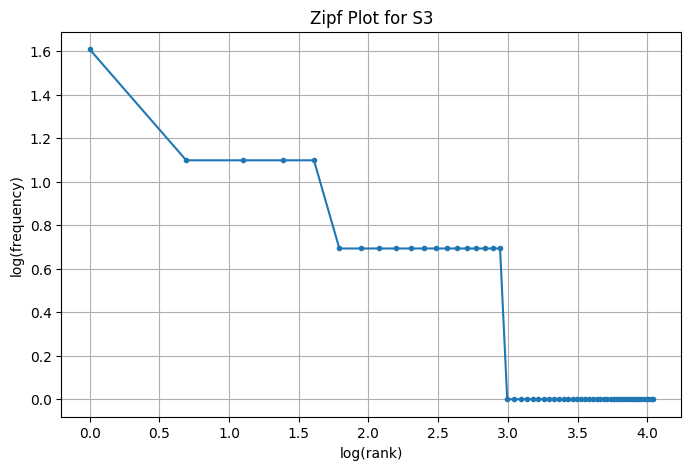


TOP 5 BIGRAMS OF S1
[(('.', 'i'), 7), (('yesterday', '.'), 4), (('.', 'the'), 4), (('.', 'it'), 3), (('was', 'working'), 2)]

TOP 5 BIGRAMS OF S3
[(('working', 'yesterday'), 2), (("n't", 'know'), 2), (('know', 'changed'), 2), (('works', 'another'), 2), (('another', 'computer'), 2)]


In [ ]:
# Your code
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams



porter = PorterStemmer()


S1 = [
    token
    for tokens in processed_df.loc[
        processed_df["Ticket_ID"] != "TOTAL", "Tokens"
    ]
    for token in tokens
]


S2 = [
    token
    for token in S1
    if not is_punct(token)
]


S3 = [
    token
    for tokens in processed_df.loc[
        processed_df["Ticket_ID"] != "TOTAL", "Final Tokens"
    ]
    for token in tokens
]


S4 = [porter.stem(token) for token in S3]




def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    return total, unique, ttr


stats = []

for name, tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    total, unique, ttr = corpus_stats(tokens)
    stats.append({
        "Set": name,
        "Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)

print("=" * 60)
print("CORPUS STATISTICS")
print("=" * 60)
display(stats_df)




s1_freq = Counter(S1)
s3_freq = Counter(S3)

print("\n" + "=" * 60)
print("TOP 10 WORDS OF S1")
print("=" * 60)
print(s1_freq.most_common(10))

print("\n" + "=" * 60)
print("TOP 10 WORDS OF S3")
print("=" * 60)
print(s3_freq.most_common(10))




ranked_s3 = s3_freq.most_common()

ranks = list(range(1, len(ranked_s3) + 1))
frequencies = [freq for word, freq in ranked_s3]

log_ranks = [math.log(r) for r in ranks]
log_frequencies = [math.log(f) for f in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o", markersize=3)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf Plot for S3")
plt.grid(True)
plt.show()




s1_bigrams = Counter(bigrams(S1))
s3_bigrams = Counter(bigrams(S3))

print("\n" + "=" * 60)
print("TOP 5 BIGRAMS OF S1")
print("=" * 60)
print(s1_bigrams.most_common(5))

print("\n" + "=" * 60)
print("TOP 5 BIGRAMS OF S3")
print("=" * 60)
print(s3_bigrams.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
TTR = Unique Tokens/Total Tokens


S1 to S2:
You remove punctuation. Total tokens fall from 180 to 151, while unique tokens only fall from 87 to 81. Since the denominator decreases substantially, TTR increases.


S2 to S3:
You additionally remove stopwords. Tokens fall from 151 to 83, and unique tokens from 81 to 57. Again, the total-token count decreases much more proportionally, so TTR rises significantly to 0.6867.


S3 to S4:
Porter stemming doesn't change the number of tokens, so both remain 83. However, it combines different words into the same stem.